# Correlations!

It should be obvious what we are going to do next.  

This is "easy". Add correlations to the graphs.

We are going to go back and use linregress to look for correlations between arsenic and other parameters.  Then we will plot them.....  


This is the hardest stuff we have done.  But we are taking two classes. Take your time and try to understand each step.  I have all the answers at the end.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from scipy import stats
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
np.set_printoptions(legacy='1.25') #removes the funny printing


Get the data in!!!

In [2]:
df=pd.read_csv('well_data.csv')

In [3]:
df.columns

Index(['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink', 'Si', 'P', 'S', 'Ca', 'Fe',
       'Ba', 'Na', 'Mg', 'K', 'Mn', 'As', 'Sr', 'F', 'Cl', 'SO4', 'Br'],
      dtype='str')

#### Let's Review
- We made a graph

Text(0, 0.5, 'Fe')

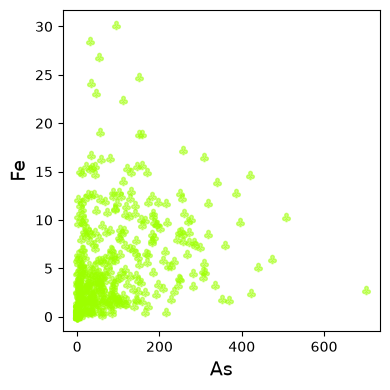

In [6]:
fig,ax=plt.subplots(layout='tight',figsize=(4,4))

Xcolumn='As'
Ycolumn='Fe'

ax.scatter(df[Xcolumn]
           ,df[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$')

ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

### Let's Review What we did.  We automated!!
- We made a path and name to pdf we want to make
    - pdf_path = 'Results/Homework.pdf' #Name a pdf file
    - remmeber to make your Results folder.  We don't error check this.
- We set the Xcolumn for the plots
    - Xcolumn='As'
- We make a list of column names we want to print by dropping the ones we don't want.
    - columns_to_plot = df.drop(columns=["Lat", "Lon", "Depth", "Drink","Well_ID", Xcolumn]).columns
- We did a with statement to open and close our pdf file
    - with PdfPages(pdf_path) as pdf:
- We did a for loop over our list of columns to plot
    - for Ycolumn in columns_to_plot:
- We made our plot
- We save the plot to the pdf file
    - pdf.savefig(dpi=200,bbox_inches='tight')
- We close the fig so we only have one fig open at a time.  We will never see the fig in our notebook
    - plt.close(fig) #closes the fig each time through to save space.
- At the end we report the sucess.

In [8]:
pdf_path = 'Results/Homework.pdf' #Name a pdf file

Xcolumn='As'
columns_to_plot = df.drop(columns=['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink',Xcolumn]).columns



with PdfPages(pdf_path) as pdf:
    for Ycolumn in columns_to_plot:
        print (Ycolumn)
        
        #filename=f'Results/{Xcolumn}.jpg' #No need to have a filename!
        
        fig,ax=plt.subplots(layout='tight',figsize=(5,5))
        
        ax.scatter(df[Xcolumn]
                   ,df[Ycolumn]
                   ,alpha=0.5
                   ,color='xkcd:bright yellow green'
                  ,marker=r'$\clubsuit$')
        
        ax.set_xlabel(Xcolumn,fontsize=14)
        ax.set_ylabel(Ycolumn,fontsize=14)
        
        pdf.savefig(dpi=200,bbox_inches='tight')  # save to a file
        
        plt.close(fig) #closes the fig each time through to save space. 

print(f'Successfully exported {len(columns_to_plot)} pages to {pdf_path}!')


Si
P
S
Ca
Fe
Ba
Na
Mg
K
Mn
Sr
F
Cl
SO4
Br
Successfully exported 15 pages to Results/Homework.pdf!


### Now let's remember linregress!

In [9]:
Xcolumn='As'
Ycolumn='Fe'

stats.linregress(df[Xcolumn],df[Ycolumn])

LinregressResult(slope=nan, intercept=nan, rvalue=nan, pvalue=nan, stderr=nan, intercept_stderr=nan)

These NaN's are becuase stats uses all the data.  pandas screens out the NaN's when it does math.  So we need to get rid of them.  There is a function dropna().  But we need to drop from when either one or both have an NaN.  I think it is easier to make a new dataframe for this.  So take just As and i and put them into a new pandas dataframe called temp.

In [11]:
dfClean=df[[Xcolumn,Ycolumn]]

In [10]:
print (dfClean.head())

         As        Fe
0       NaN       NaN
1       NaN       NaN
2       NaN       NaN
3  78.97747  1.260031
4       NaN       NaN


But we still have nan's.  lets make it with Nan dropped.  If either have an NaN it removes the row

In [12]:
dfClean=df[[Xcolumn,Ycolumn]].dropna()

In [14]:
print (dfClean.head())

           As         Fe
3   78.977470   1.260031
6   28.070949   1.843156
8   96.885674  11.740445
9   80.627214   8.923465
11  77.006865   6.349396


Now try linregress again but on the new cleaned data

In [15]:
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])

LinregressResult(slope=0.012996899643346852, intercept=4.390525620904395, rvalue=0.25604180950141986, pvalue=1.6310638519923062e-07, stderr=0.0024382468890464404, intercept_stderr=0.33008481223672703)

#### Remember we set the output to LinResult

In [16]:
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])

## f-string formatting
- AI has been trying to tell us to stop using .format and use f-string formats
- Let's try
- The difference is:
    - You put an f before the quotes
    - You put the variable in the {} not at the end
    - supposedly easier to read
    - Since we want four lines I am using what is called implicit concatenation so that it joins everything in the brackets
- Let's Try!!!!
- Let's make the text output for our box

In [19]:
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)
print(textstr)

m=0.013
b=4.391
$r^2$=0.066
p=0.000


### Add the text box!
Now lets print our one graph with the data.  For these look at our favorite recipes 
http://matplotlib.org/users/recipes.html
and scroll all the way to the bottom.  This is a reminder of what you need to do.  

1.  Make your text string
2.  Make props to give you properties for the box.
3.  pass ax.text and place the box.  


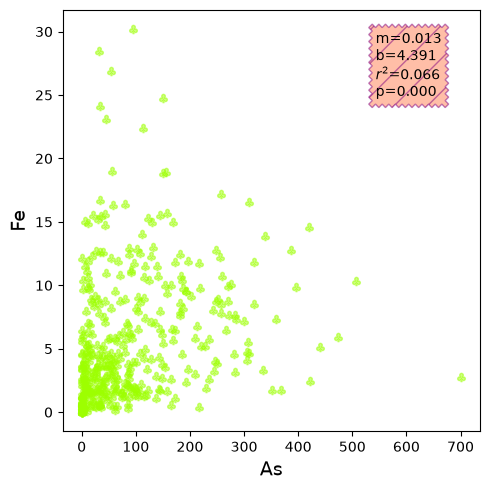

In [55]:
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

fig,ax=plt.subplots(layout='tight',figsize=(5,5))

ax.scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$')

LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)


ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

ax.text(0.75,0.95
        ,textstr
        ,transform=ax.transAxes
        ,fontsize=10
        ,verticalalignment='top'
        ,bbox=props)     #add the text box

plt.show()

## How does ax.text work?
- transform=ax.transAxes converts from units to percent when included.  If you exclude it, it plots in the axis units.  Otherwise the fraction
- horizontalalignment=ha='right, center, left'
- vertical alignemnt =  va = "top, center, bottom'

put you box in the middle!



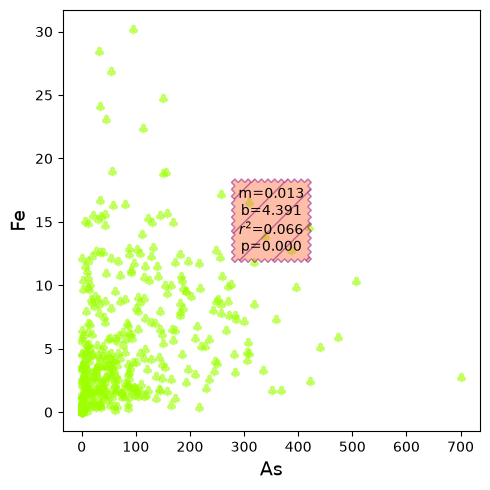

In [54]:
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

fig,ax=plt.subplots(layout='tight',figsize=(5,5))

ax.scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$')

LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)


ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

ax.text(0.5,0.5,textstr,transform=ax.transAxes
        ,fontsize=10,ha='center',va='center'
        ,bbox=props)     #add the text box

plt.show()

### Add the best fit line!  

Now we just need to add the best fit line.  You have the m and b from linregress. 

Remember we talked about what to use for x_fit.  I found the answer to what works best.  Rememebr I said you could use
1.  your x-values
1.  the min and max of the x values
2.  A nice array of numbers from np.linspace set with your min and max of the x values
1.  Random numbers you make up.

I found out why linspace of min and max of the x values works the best.  If you use all the x-values it adds a lot of points to the line and then the line looks funny.  If you use the min and max of the x-values only it won't work for higher order lines.   I would do x_fit=np.linpsace([df[x].min(), df[x].max()). 

- You get a nice line
- You are future proofed.  



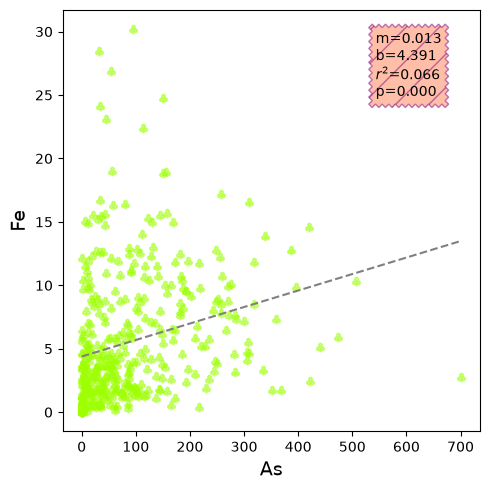

In [118]:
# Set and clean data
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

# turn on plot
fig,ax=plt.subplots(layout='tight',figsize=(5,5))

# Scatter plot
ax.scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$'
          ,label='Data')

# Regression
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

ax.text(0.75,0.95, textstr, transform=ax.transAxes
        ,fontsize=10 ,va='top' ,bbox=props)     #add the text box

plt.show()

## Make a PDF!!!!!!
- Now go back and make your pdf!
- remember your for loop
- put in the Results folder
- **THINK ABOUT WHAT IS INSIDE AND OUTSIDE THE FOR LOOP!!!!!!**
- look at your plots!  

Successfully exported 15 pages to Results/DataWithBestFit.pdf!


# Do we really need to look at the data?  
- I love looking at plots and data
- But imagine you had 100,000 correlations.  Would you want to look at all of them? Probaly Not
- What if we could just rank the p-values and r$^2$?
- Let's try

#### How to make a new Dataframe and save to excel!
1.  AI yelled at me for using a slow method!  Made sense in my mind!
2.  Let's try and do this correctly!
3.  We need to make a dictionary.  We don't use these much but will here. 
4.  We make an empty dictionary
5.  We save the data to a dictionary each time through the loop
6.  We save ALL OF OUR DATA! and sort it!
7.  We convert the dictionary to a dataframe
8.  We save to excel!


In [3]:
pdf_path = 'Results/DataWithBestFit.pdf' #Name a pdf file
excel_path = 'Results/SummaryData.xlsx' #Name a pdf file
results_list = [] # List to collect regression results

Xcolumn='As'

columns_to_plot = df.drop(columns=['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink',Xcolumn ]).columns

# Text box properties
props=dict(boxstyle ='roundtooth,pad=0.5'
          ,facecolor ='coral'
          ,edgecolor ='purple'
          ,alpha =0.5
          ,hatch ='/')  #properties of the text box

with PdfPages(pdf_path) as pdf:
    for Ycolumn in columns_to_plot :

        dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
        
        # turn on plot
        fig,ax=plt.subplots(layout='tight',figsize=(5,5))
        
        # Scatter plot
        ax.scatter(dfClean[Xcolumn]
                   ,dfClean[Ycolumn]
                   ,alpha=0.5
                   ,color='xkcd:bright yellow green'
                  ,marker=r'$\clubsuit$'
                  ,label='Data')
        
        # Regression
        LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
        textstr= (
            f'm={LinResult.slope:.3f}\n'
            f'b={LinResult.intercept:.3f}\n'
            f'$r^2$={LinResult.rvalue**2:.3f}\n'
            f'p={LinResult.pvalue:.3f}'
        )
        results_list.append({
            'Xcolumn': Xcolumn,
            'Ycolumn': Ycolumn,
            'r2': LinResult.rvalue**2,
            'rvalue': LinResult.rvalue,
            'pvalue': LinResult.pvalue,
            'slope': LinResult.slope,
            'intercept': LinResult.intercept,
            'stderr': LinResult.stderr,
            'n_samples': len(dfClean),
        })
        
        ## Best fit line
        x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
        y_fit = x_fit*LinResult.slope + LinResult.intercept
        
        ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')
        
        # Label Plot
        ax.set_xlabel(Xcolumn,fontsize=14)
        ax.set_ylabel(Ycolumn,fontsize=14)
        
        ax.text(0.95,0.95, textstr, transform=ax.transAxes
                ,fontsize=10 ,va='top', ha='right', bbox=props)     #add the text box

        # Save and close
        pdf.savefig(dpi=200,bbox_inches='tight')  # save to a file        
        plt.close(fig) #closes the fig each time through to save space. 

df_r2 = (
    pd.DataFrame(results_list)
    .sort_values(by='r2', ascending=False)
)
df_r2.to_excel(excel_path,index=False)

print(f'Successfully exported {len(columns_to_plot)} pages to {pdf_path}!')
print(f'Successfully exported {len(df_r2)} data to {excel_path}!')


Successfully exported 15 pages to Results/DataWithBestFit.pdf!
Successfully exported 15 data to Results/SummaryData.xlsx!


# Great Job.
## You just p-hacked your data!
I just taught you how to p-hack your data.  p-hacking is wrong.  I think Taylor Swift said it correctly.  

They say I did something bad

Then why's it feel so good?


p-hacking is bad but it is what people do! https://bitesizebio.com/31497/guilty-p-hacking/   So as long as you are concious of what you are doing it is sort of ok. You should really start with a hypothesis and then look for correlations.  But it is also alright to explore the data this way.  Just be cognizant of the weaknesses.

But this is great.  we have all the data.  



### here is the r$^2$!

In [69]:
df_r2

,Xcolumn,Ycolumn,r2,rvalue,pvalue,slope,intercept,stderr,n_samples
10,As,Sr,0.155595,0.394455,1.327101e-16,0.351605,155.235389,0.040701,407
3,As,Ca,0.154148,0.392616,1.885646e-16,77.962612,34136.931251,9.074815,407
1,As,P,0.069488,0.263605,6.760020e-08,0.002344,0.599083,0.000426,407
4,As,Fe,0.065557,0.256042,1.631064e-07,0.012997,4.390526,0.002438,407
5,As,Ba,0.059968,0.244883,5.689137e-07,0.130660,77.359823,0.025706,407
6,As,Na,0.053342,-0.230958,2.490748e-06,-0.040692,33.091150,0.008518,407
0,As,Si,0.037977,-0.194877,7.576966e-05,-19.419757,41842.883028,4.856790,407
9,As,Mn,0.032770,0.181026,2.414060e-04,0.001745,1.152794,0.000471,407
13,As,SO4,0.021915,-0.148036,3.919941e-03,-0.020900,11.173792,0.007201,378
14,As,Br,0.018130,-0.134648,7.993404e-03,-0.000117,0.068414,0.000044,387


## This is really p-hacking.  You almost don't need the graphs.  Just the p-values!


# NEW SECTION!   

## Make lots of graphs next to each other!

### This is our Goal

#### Now let's make a plot of our top fits!

Now we want to take the best 4 or 6 r$^2$ values and plot them on one sheet.  remember we have the data now!!!!

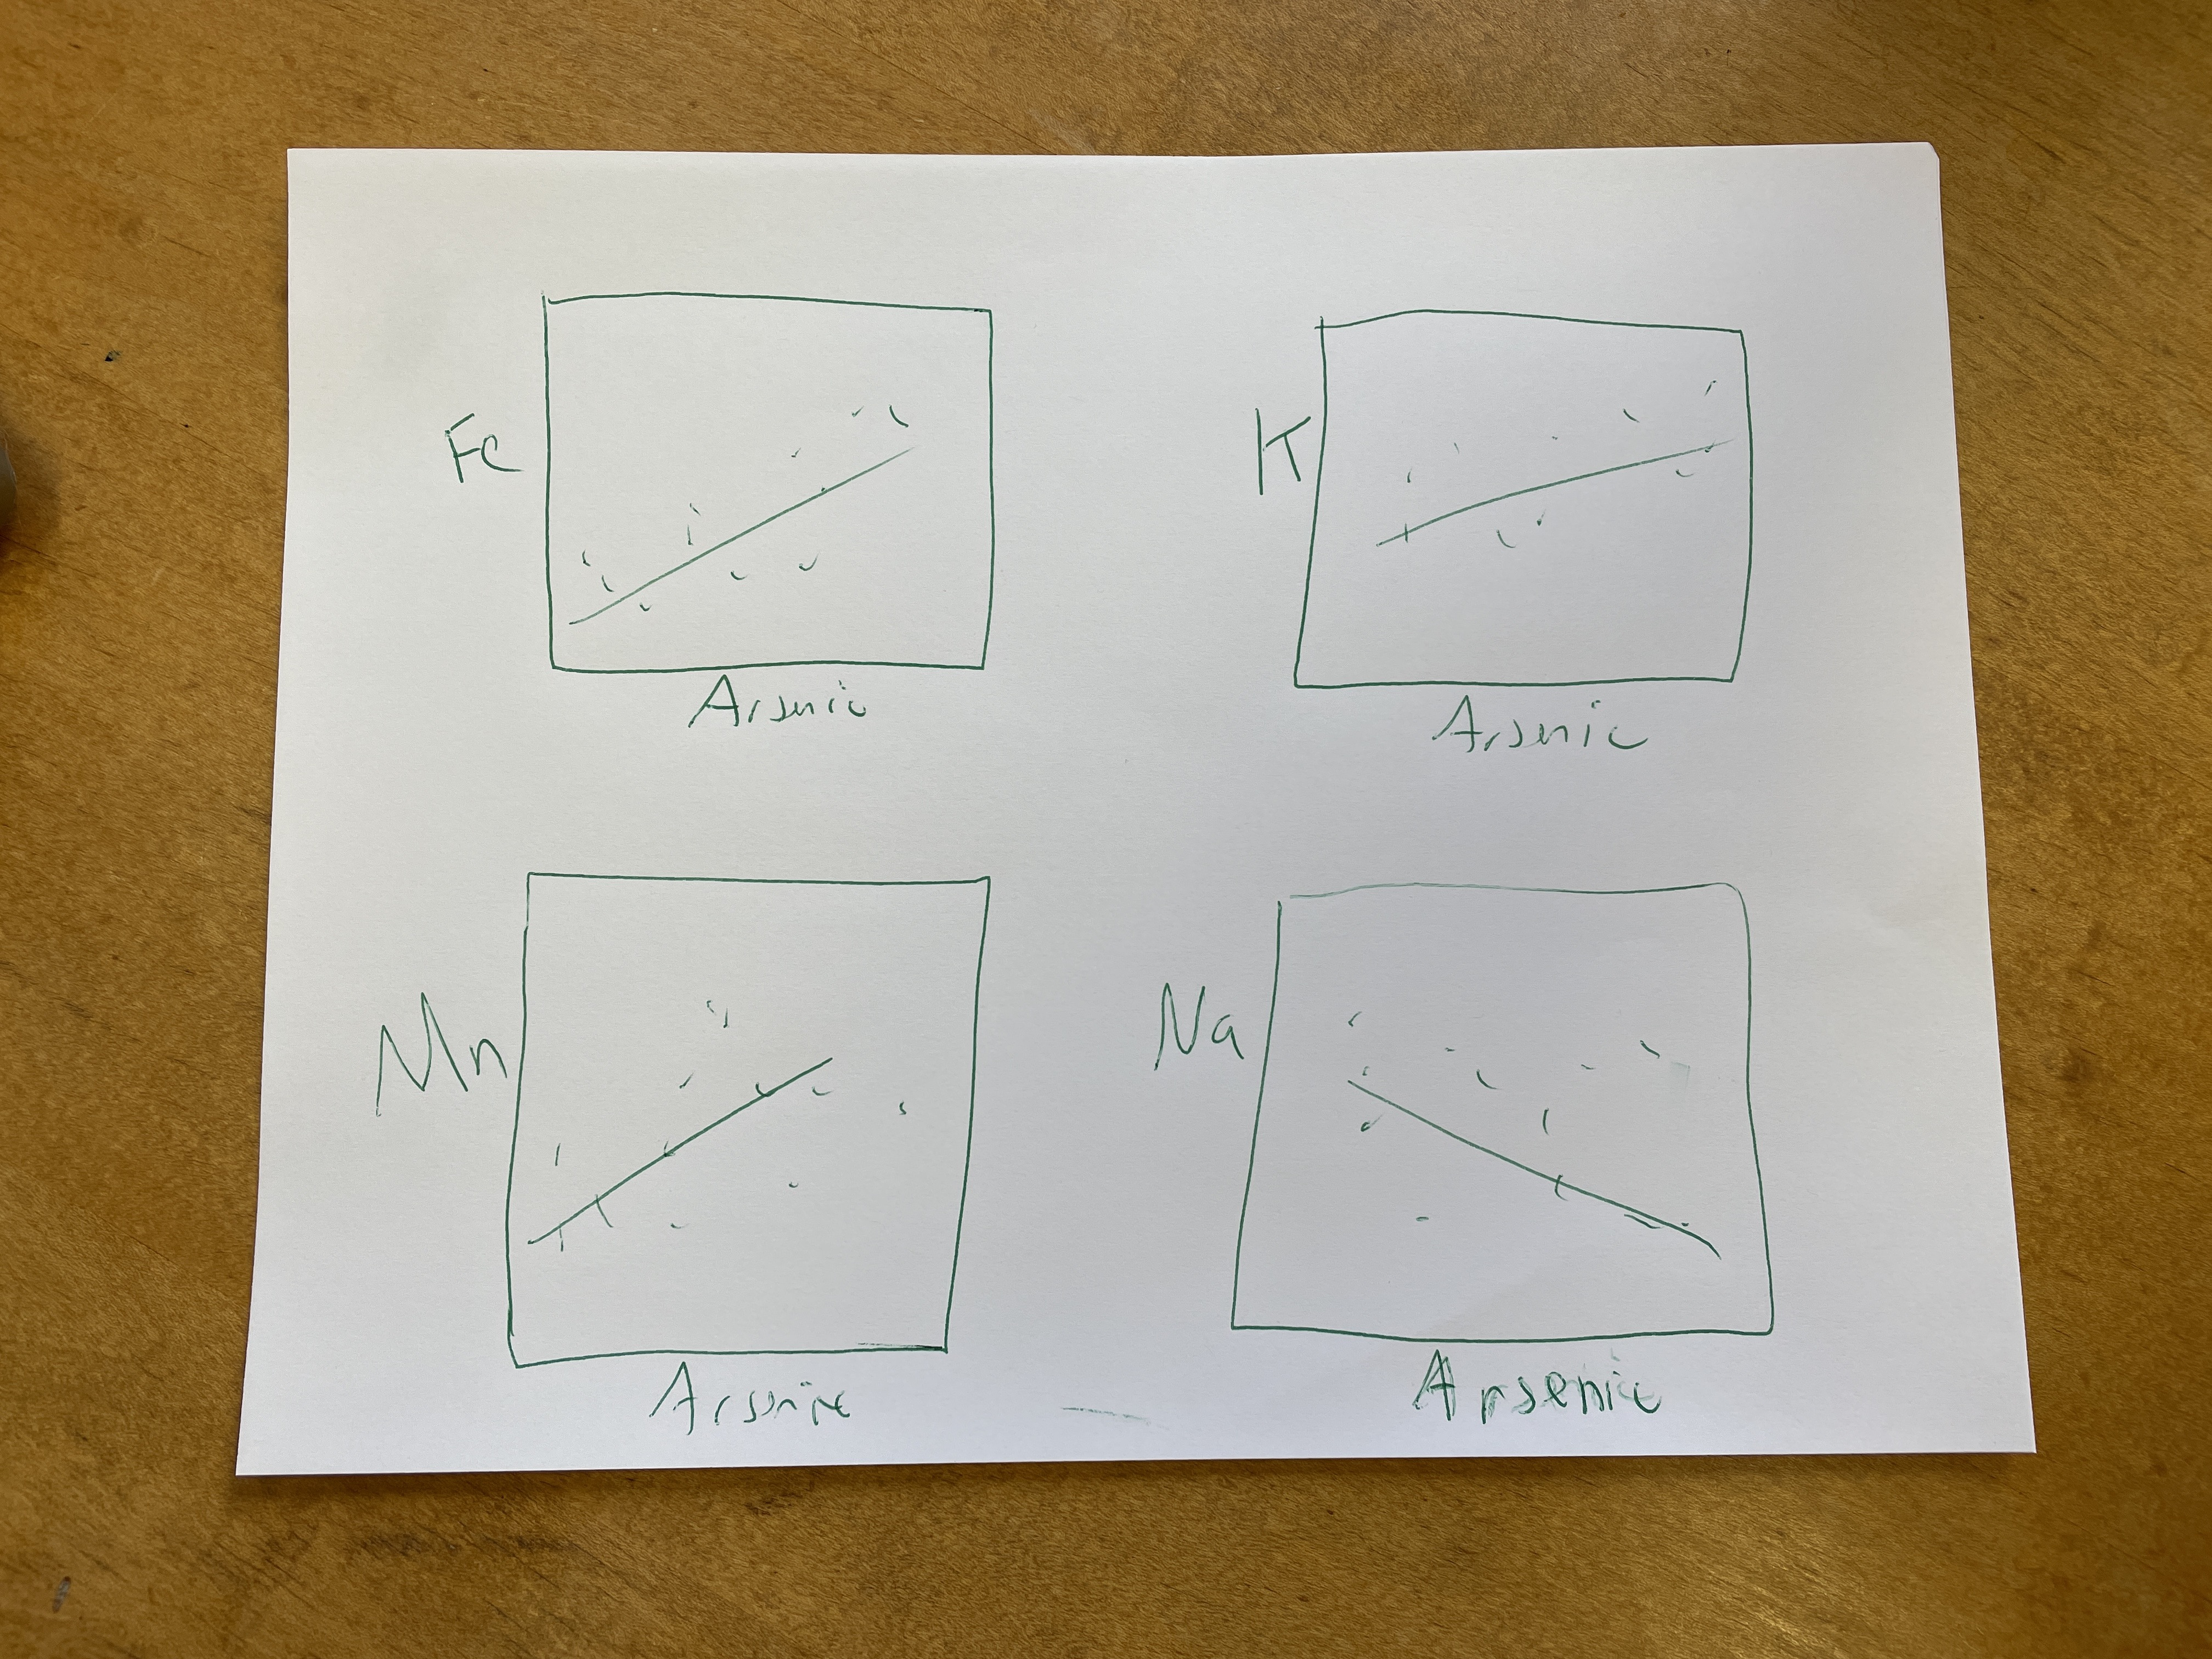

In [28]:
from IPython.display import Image
Image(filename='Figure-schematic.JPG',width=500)

## 4 graphs. one page. In a grid
Now lets put our top 4 correlations onto one page!  I will walk you through it.  Grab your plot from above but with no for loop or datafile stuff

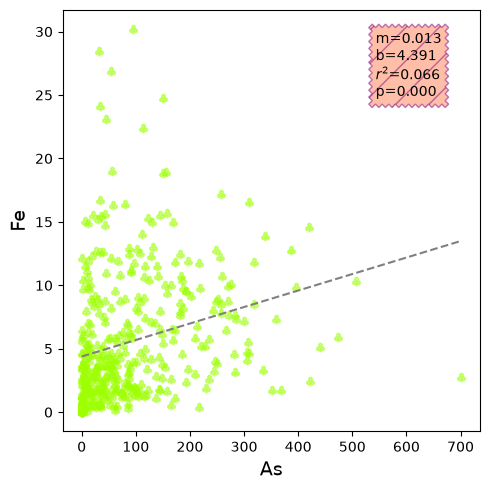

In [115]:
# Set and clean data
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

# turn on plot
fig,ax=plt.subplots(layout='tight',figsize=(5,5))

# Scatter plot
ax.scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$'
          ,label='Data')

# Regression
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

ax.text(0.75,0.95, textstr, transform=ax.transAxes
        ,fontsize=10 ,va='top' ,bbox=props)     #add the text box

plt.show()



## Goal 

-  We want 4 graphs nicely lined up on one page to print. 
-  make the subplots 2,2 so we can show four graphs. 
-  We are going to use a for loop like last time.  
-  So lets make a list of elemsents we want to graph.  
-  Grab the top four r$^2$ elements from above.     

### First make your subplots(2,2)
- fig,ax=plt.subplots(2,2, layout='tight',figsize=(5,5))
- You will get an error because ax is a two-d array. 
### You are going to get an error!!

AttributeError: 'numpy.ndarray' object has no attribute 'scatter'

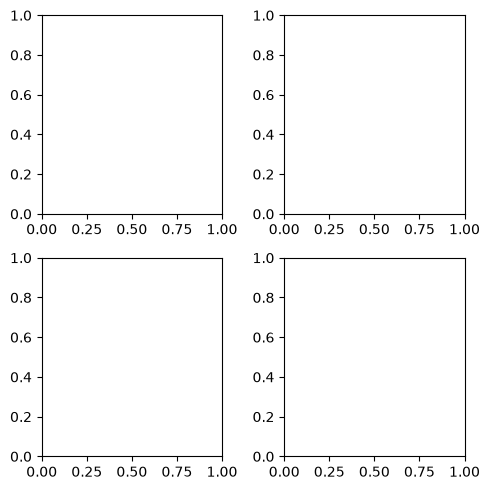

In [114]:
# Set and clean data
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

# turn on plot
fig,ax=plt.subplots(2,2, layout='tight',figsize=(5,5))

# Scatter plot
ax.scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$'
          ,label='Data')

# Regression
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

ax.text(0.75,0.95, textstr, transform=ax.transAxes
        ,fontsize=10 ,va='top' ,bbox=props)     #add the text box

plt.show()

### The problem is now your ax is a 2d array!!!!
- Where you call ax after the initial value where you set it make it ax[0,0]
- there are a few hidden ax calls!



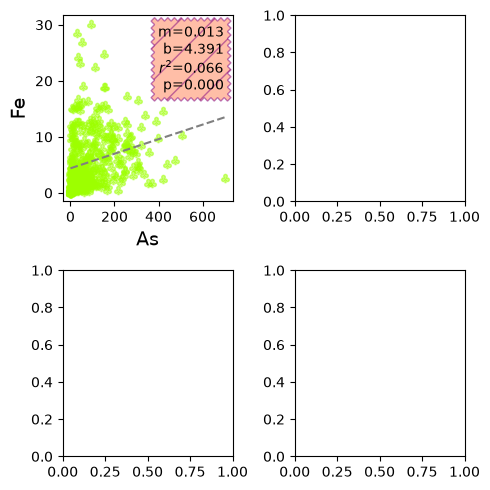

In [126]:
# Set and clean data
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

# turn on plot
fig,ax=plt.subplots(2,2, layout='tight',figsize=(5,5))

# Scatter plot
ax[0,0].scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$'
          ,label='Data')

# Regression
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax[0,0].plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax[0,0].set_xlabel(Xcolumn,fontsize=14)
ax[0,0].set_ylabel(Ycolumn,fontsize=14)

ax[0,0].text(0.95,0.95, textstr, transform=ax[0,0].transAxes
        ,fontsize=10 ,va='top',ha='right' ,bbox=props)     #add the text box

plt.show()


### Next step

- That worked nicely. Now go back up and make graph on the next graph over!
- Try [0,1], [1,0], [1,1]
-  Plus make it bigger using f,figsize=(10,10)

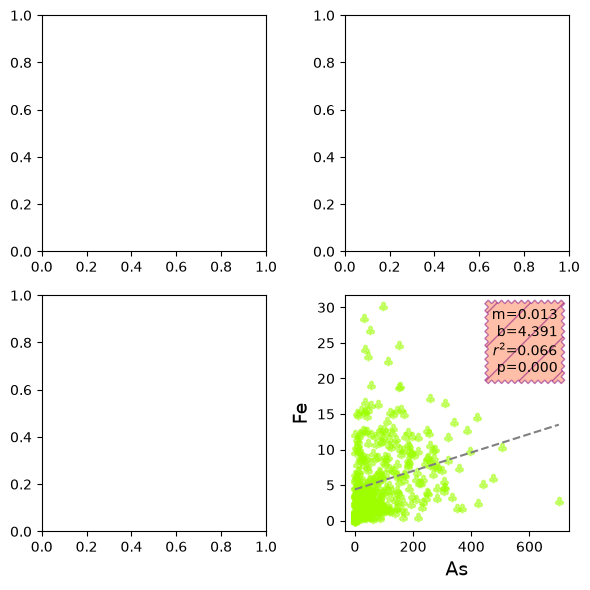

### That worked nicely. 

But we have a problem.  We have our list of 4 elements we want to plot.  But we have a 2x2 matrix to put them into when using ax.

#### confusing!!!!

use the script below to see how the numbering works

Change the nrows and ncols and see what you get!!!!

copy the script.  Change nrows and ncols and see what happens

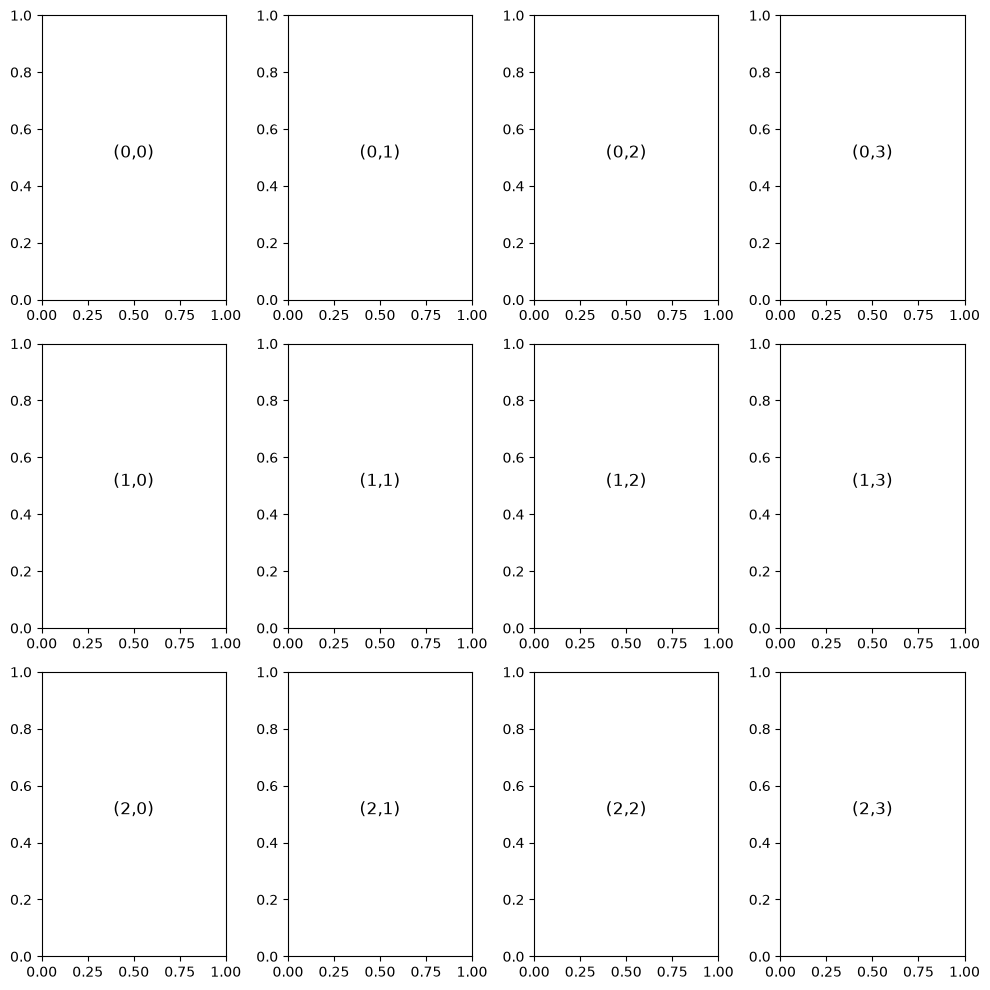

In [113]:
nrows=3  # CHANGE ME!
ncols=4  # CHANGE ME!

fig,ax=plt.subplots(nrows,ncols,layout='tight',figsize=(10,10))

for i in np.arange(nrows):
    for j in np.arange(ncols):
        ax[i, j].text(0.5, 0.5, f'({i},{j})',
                      fontsize=12, ha='center')

### Follow me.
this is the hard part.  We have a list of elements. we want plotted.  It is a one-dimensional list with a length.  But we want to put them on a two dimensional array of graphs.  To continue our example above 
-  we are going to start with flatten! 
-  this flattens an array. It takes a 2d array and makes it into a 1d array 
-  We can turn ax into a 1d array.

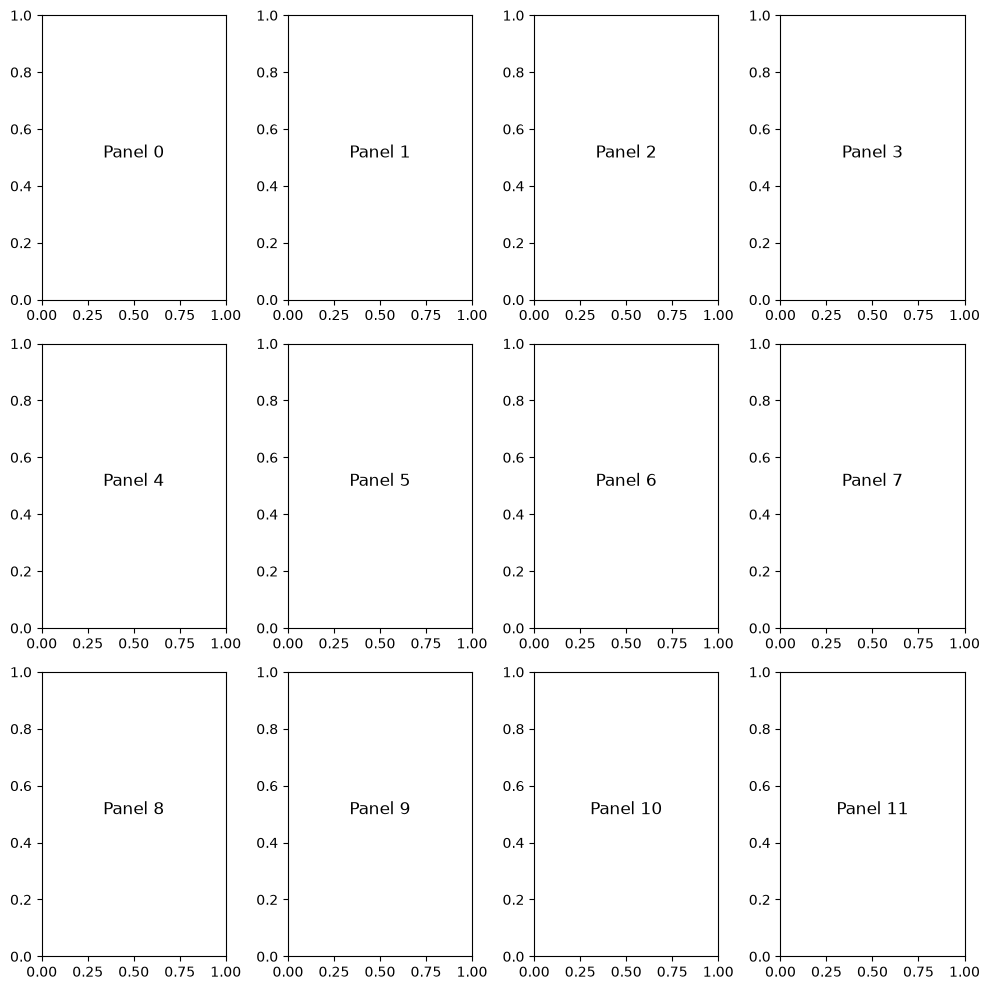

In [83]:
nrows=3
ncols=4
ngraphs=nrows*ncols

fig,ax2d=plt.subplots(nrows,ncols,layout='tight',figsize=(10,10))
fig.set_size_inches(10,10)
ax=ax = ax2d.flatten()  ### FLATTEN!!!!

for count in np.arange(ngraphs):
    ax[count].text(0.5, 0.5, f'Panel {count}',
                      fontsize=12, ha='center')

### Did i lose you yet?????
- We are going to make it more pythonic!!!!!
- We are going to do it all in an enumerate loop.
- This is crazy and comes back to "I said this was going to be important!!!"
- AND we only need a plain ax call.  The enumerate and flat takes care of it!

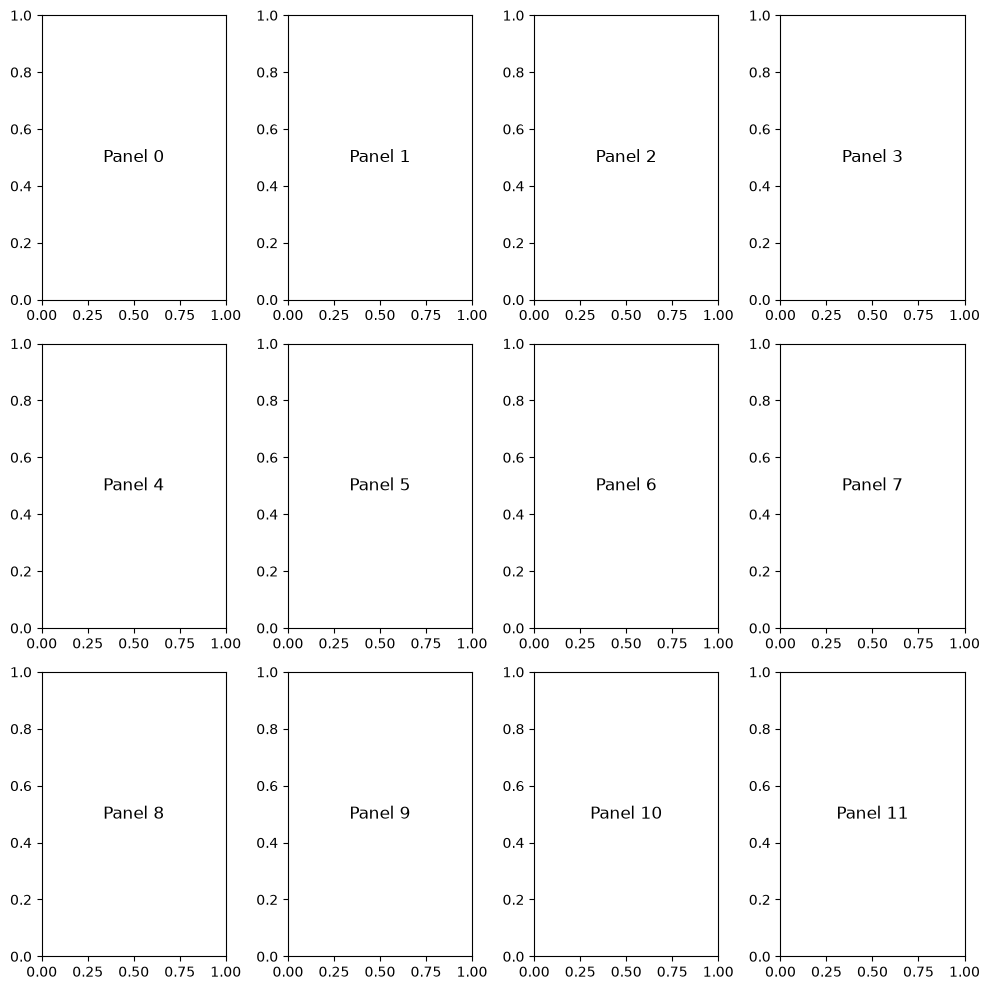

In [97]:
nrows=3
ncols=4

fig,ax2d=plt.subplots(nrows,ncols,layout='tight',figsize=(10,10))

for count, ax in enumerate(ax2d.flat):
  ax.text(0.5, 0.5, f'Panel {count}', fontsize=12, ha='center', va='center')

plt.show()

## i hope you are not lost?
"Maybe we got lost in translation, maybe I asked for too much"?

- Can we automatically add our top correlations?

#### Remember we saved our r2 data?

In [85]:
df_r2

,Xcolumn,Ycolumn,r2,rvalue,pvalue,slope,intercept,stderr,n_samples
10,As,Sr,0.155595,0.394455,1.327101e-16,0.351605,155.235389,0.040701,407
3,As,Ca,0.154148,0.392616,1.885646e-16,77.962612,34136.931251,9.074815,407
1,As,P,0.069488,0.263605,6.760020e-08,0.002344,0.599083,0.000426,407
4,As,Fe,0.065557,0.256042,1.631064e-07,0.012997,4.390526,0.002438,407
5,As,Ba,0.059968,0.244883,5.689137e-07,0.130660,77.359823,0.025706,407
6,As,Na,0.053342,-0.230958,2.490748e-06,-0.040692,33.091150,0.008518,407
0,As,Si,0.037977,-0.194877,7.576966e-05,-19.419757,41842.883028,4.856790,407
9,As,Mn,0.032770,0.181026,2.414060e-04,0.001745,1.152794,0.000471,407
13,As,SO4,0.021915,-0.148036,3.919941e-03,-0.020900,11.173792,0.007201,378
14,As,Br,0.018130,-0.134648,7.993404e-03,-0.000117,0.068414,0.000044,387


### Can you give me the Ycolumn for row 0? with the highest r$^2$?

In [96]:
df_r2.iloc[0]['Ycolumn']

'Sr'

### Now can we write what element we will want plotted on each graph?

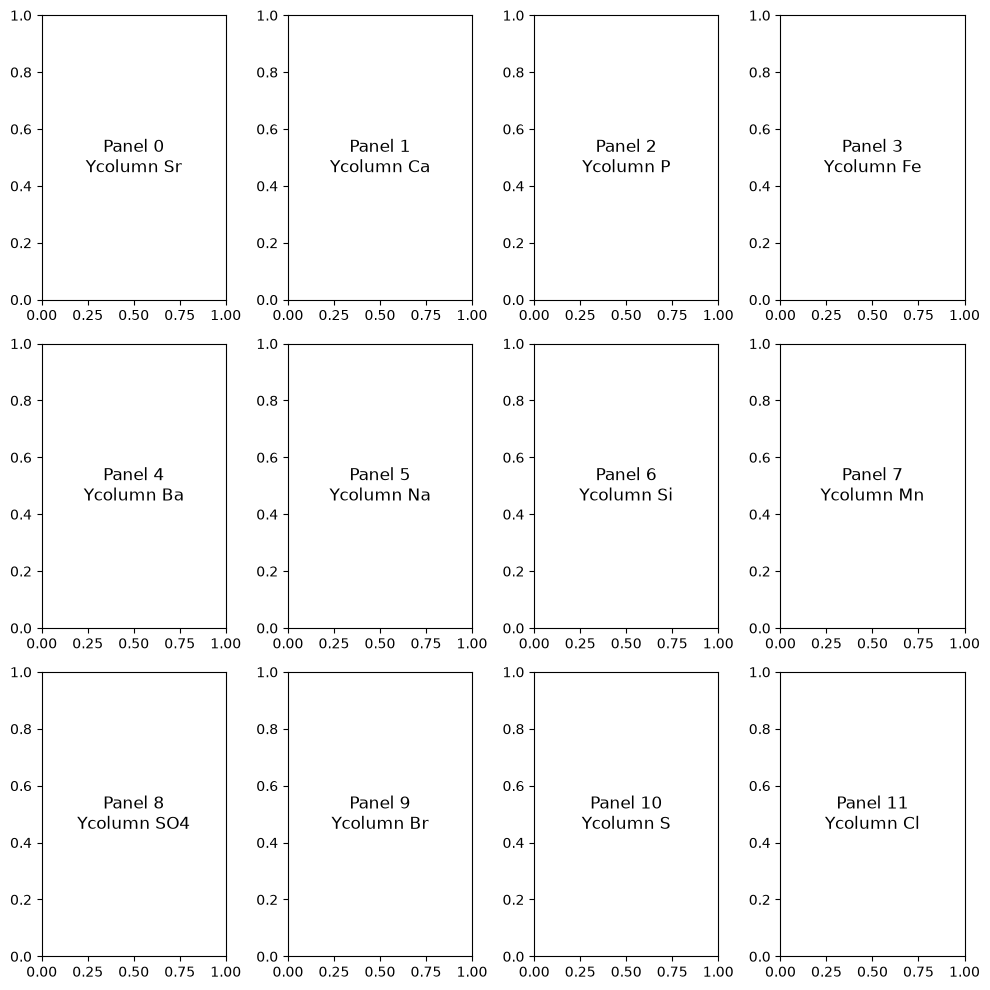

In [106]:
nrows=3
ncols=4

fig,ax2d=plt.subplots(nrows,ncols,layout='tight',figsize=(10,10))

for count, ax in enumerate(ax2d.flat):
    textstr=(
        f'Panel {count}\n'
        f'Ycolumn {df_r2.iloc[count]["Ycolumn"]}'
            )
    ax.text(0.5, 0.5, textstr, fontsize=12, ha='center', va='center')

plt.show()

### Now you are ready!!!! Can you make these four plots???

- make these four plots!
- Automatically!
    - Set your Xcolumn
    - make an automatic filename
- Add the letters

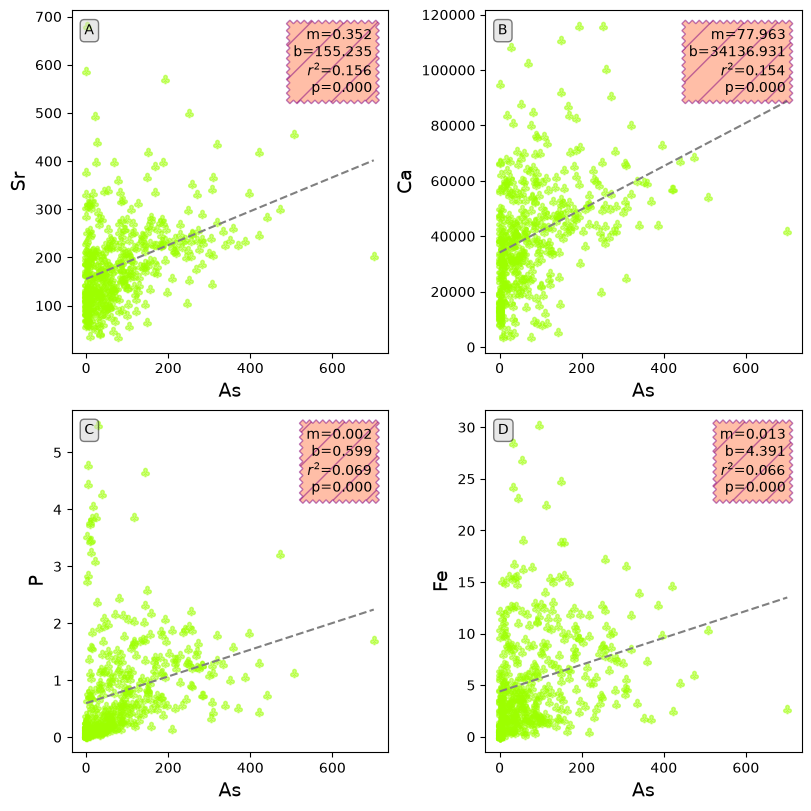

### That is beautiful!  


### Can we do six plots?

# We are not stopping!
### What if we wanted to check correlations against more than As?????

### Correlation Matrices!!!!

- Everyone versus Everyone!!
- First in  Pandas
- corr creates a dataframe that is just r values!!!!

In [4]:
df.columns

Index(['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink', 'Si', 'P', 'S', 'Ca', 'Fe',
       'Ba', 'Na', 'Mg', 'K', 'Mn', 'As', 'Sr', 'F', 'Cl', 'SO4', 'Br'],
      dtype='str')

In [5]:
# Select key geochemical variables

columns_to_plot = df.drop(columns=['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink']).columns


# Calculate pairwise Pearson r values
corr_matrix = df[columns_to_plot].corr()

print(corr_matrix.round(2))
corr_matrix.to_excel('Results/corr_matrix.xlsx')

       Si     P     S    Ca    Fe    Ba    Na    Mg     K    Mn    As    Sr  \
Si   1.00  0.15 -0.06  0.02 -0.11 -0.21  0.16  0.17 -0.10 -0.03 -0.19  0.12   
P    0.15  1.00 -0.18  0.10  0.26  0.00  0.06  0.37  0.10 -0.29  0.26  0.36   
S   -0.06 -0.18  1.00  0.38 -0.02  0.49  0.36  0.45  0.41  0.31 -0.12  0.20   
Ca   0.02  0.10  0.38  1.00  0.20  0.62 -0.02  0.61  0.17  0.43  0.39  0.79   
Fe  -0.11  0.26 -0.02  0.20  1.00  0.47 -0.13  0.13  0.04  0.16  0.26  0.20   
Ba  -0.21  0.00  0.49  0.62  0.47  1.00  0.14  0.43  0.53  0.36  0.24  0.47   
Na   0.16  0.06  0.36 -0.02 -0.13  0.14  1.00  0.29  0.26 -0.12 -0.23  0.14   
Mg   0.17  0.37  0.45  0.61  0.13  0.43  0.29  1.00  0.39  0.18 -0.03  0.65   
K   -0.10  0.10  0.41  0.17  0.04  0.53  0.26  0.39  1.00  0.02  0.01  0.19   
Mn  -0.03 -0.29  0.31  0.43  0.16  0.36 -0.12  0.18  0.02  1.00  0.18  0.19   
As  -0.19  0.26 -0.12  0.39  0.26  0.24 -0.23 -0.03  0.01  0.18  1.00  0.39   
Sr   0.12  0.36  0.20  0.79  0.20  0.47  0.14  0.65 

### Can we visualize this?
- Go look in excel first

## Seaborn
- Seaborn is a graphing package that takes matplotlib and makes some fancier graphs
- https://seaborn.pydata.org/examples/index.html
- We are going to take our correlation matrix and make a heatmap!

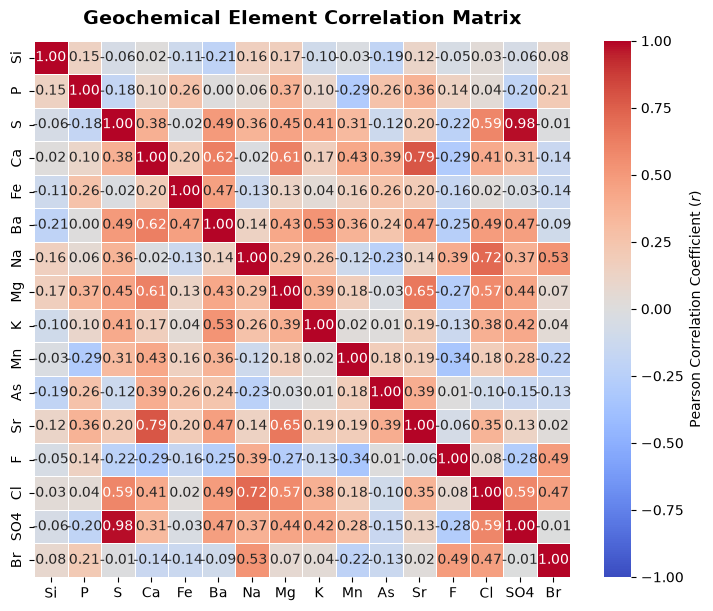

In [6]:
columns_to_plot = df.drop(columns=['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink']).columns

# Calculate pairwise Pearson r values
corr_matrix = df[columns_to_plot].corr()

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',  # Diverging colormap (-1 blue, 0 white, +1 red)
    vmax=1.0,
    vmin=-1.0,
    annot=True,  # Display numerical values inside boxes
    fmt='.2f',  # Round cell values to 2 decimals
    square=True,  # Keep cells perfectly square
    linewidths=0.5,  # Grid line spacing
    cbar_kws={'label': "Pearson Correlation Coefficient ($r$)"},
    ax=ax,
)

ax.set_title(
    'Geochemical Element Correlation Matrix', fontsize=14, weight='bold', pad=12
)

#Save and display
fig.savefig('Results/Correlation_Matrix.jpg', dpi=200, bbox_inches='tight')
plt.show()

### Masking
- The matrix is repetitive.
- It is easy to read but data is shown twice.
- People sometimes only show 1/2.
- Create a mask for the upper triangle
    - mask = np.triu(np.ones_like(corr, dtype=bool))
    - Then pass mask=mask

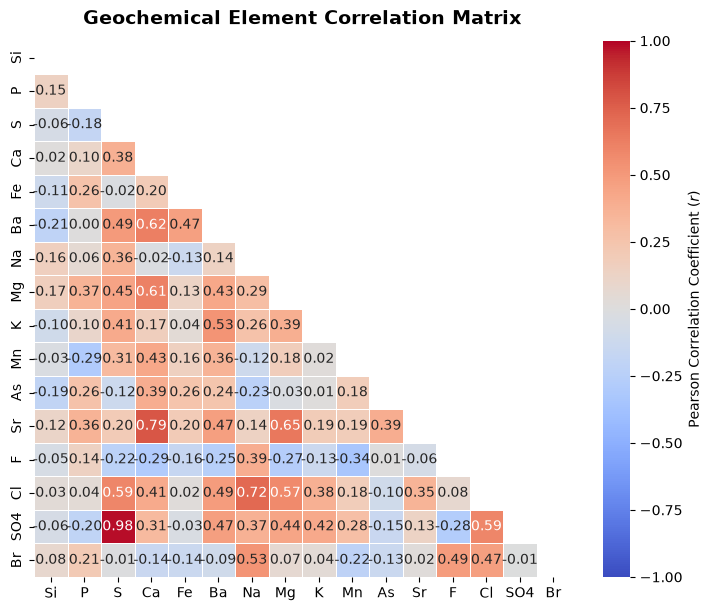

In [9]:
columns_to_plot = df.drop(columns=['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink']).columns

# Calculate pairwise Pearson r values
corr_matrix = df[columns_to_plot].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',  # Diverging colormap (-1 blue, 0 white, +1 red)
    vmax=1.0,
    vmin=-1.0,
    mask=mask,
    annot=True,  # Display numerical values inside boxes
    fmt='.2f',  # Round cell values to 2 decimals
    square=True,  # Keep cells perfectly square
    linewidths=0.5,  # Grid line spacing
    cbar_kws={'label': "Pearson Correlation Coefficient ($r$)"},
    ax=ax,
)

ax.set_title(
    'Geochemical Element Correlation Matrix', fontsize=14, weight='bold', pad=12
)

#Save and display
fig.savefig('Results/Correlation_Matrix.jpg', dpi=200, bbox_inches='tight')
plt.show()

## Seaborn Pair plots
- We plotted As versus other paramters
- Instead we can do a correlation matrix with plots
- You can only do a few columns becuase it will crash!
- Let's try!
- This time list the columns you want to plot!
- You do not use subplots!!!!

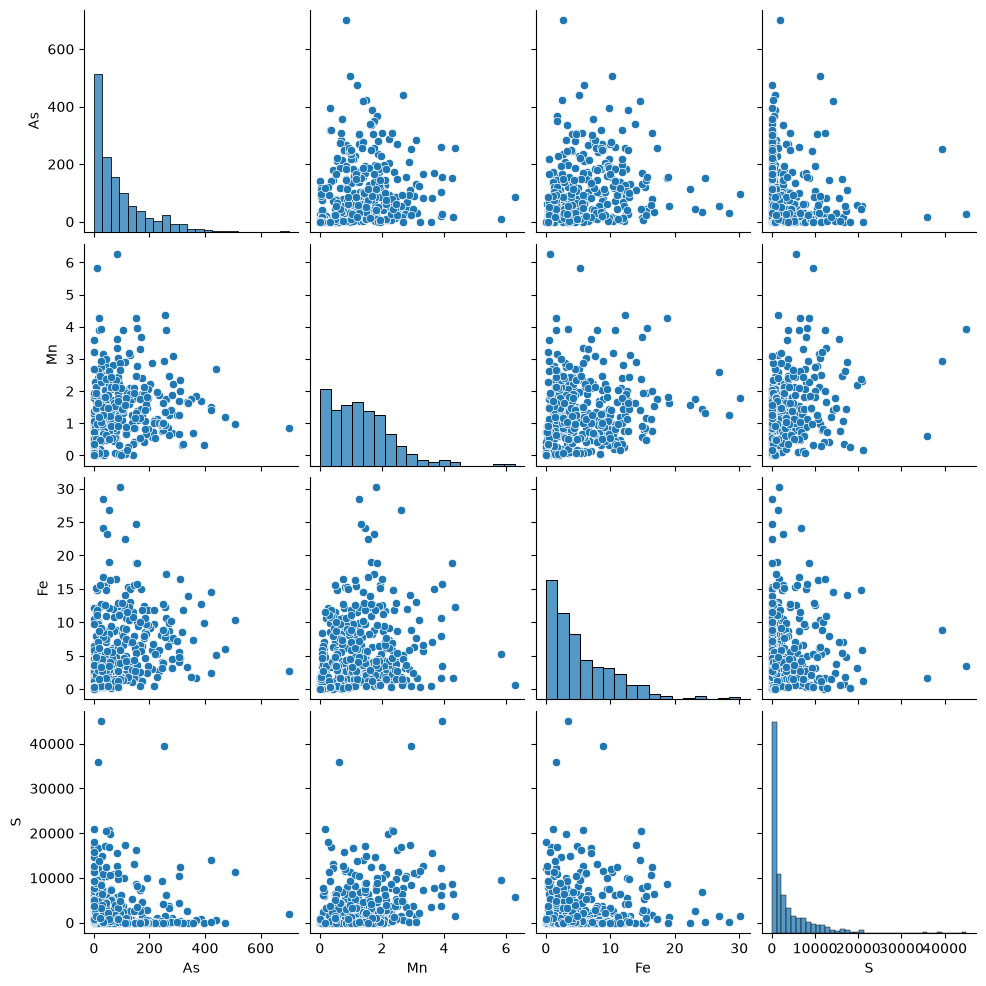

In [10]:
columns_to_plot = ['As', 'Mn', 'Fe', 'S', 'Drink']

# Create the pairplot
g = sns.pairplot(df[columns_to_plot ])

# 4. Save and show
g.savefig('Results/Pairplot_Summary.jpg', dpi=200, bbox_inches='tight')
plt.show()

### A few cool tricks
- You can only show half the matrix by calling corner=True
- If you pass a categorical value you can then color the dots by that.  I will pass drink
- I will lower the alpha on the symbols so they plot nice
    - plot_kws={'alpha': 0.5, 's': 25}

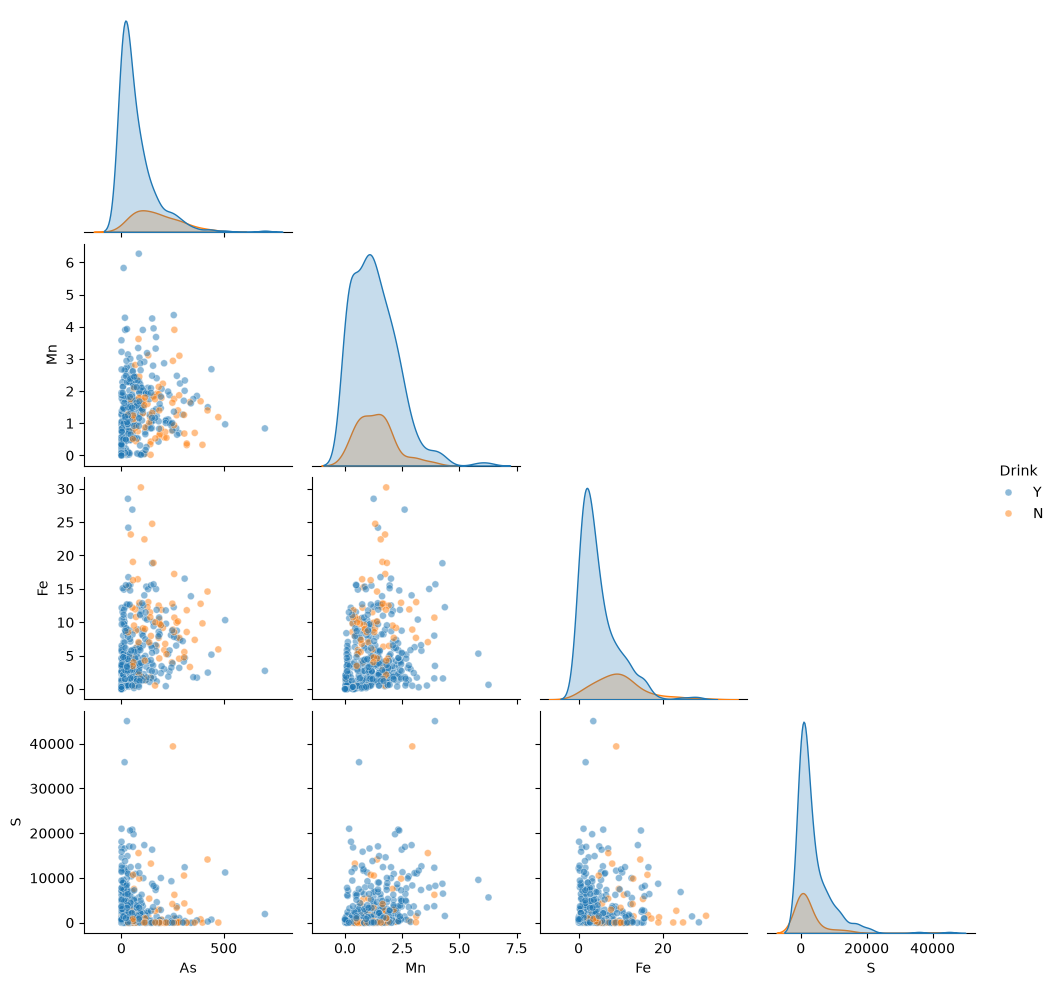

In [12]:
columns_to_plot = ['As', 'Mn', 'Fe', 'S', 'Drink']

# Create the pairplot
g = sns.pairplot(df[columns_to_plot ]
                ,hue='Drink'
                ,corner=True
                ,plot_kws={'alpha': 0.5, 's': 25})

# 4. Save and show
g.savefig('Results/Pairplot_Summary.jpg', dpi=200, bbox_inches='tight')
plt.show()

# ANSWERS

In [6]:
pdf_path = 'Results/DataWithBestFit.pdf' #Name a pdf file

Xcolumn='As'

columns_to_plot = df.drop(columns=['Well_ID', 'Lat', 'Lon', 'Depth', 'Drink',Xcolumn ]).columns

# 2. Text box properties
props=dict(boxstyle ='roundtooth,pad=0.5'
          ,facecolor ='coral'
          ,edgecolor ='purple'
          ,alpha =0.5
          ,hatch ='/')  #properties of the text box

with PdfPages(pdf_path) as pdf:
    for Ycolumn in columns_to_plot :

        dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
        
        # turn on plot
        fig,ax=plt.subplots(layout='tight',figsize=(5,5))
        
        # Scatter plot
        ax.scatter(dfClean[Xcolumn]
                   ,dfClean[Ycolumn]
                   ,alpha=0.5
                   ,color='xkcd:bright yellow green'
                  ,marker=r'$\clubsuit$'
                  ,label='Data')
        
        # Regression
        LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
        textstr= (
            f'm={LinResult.slope:.3f}\n'
            f'b={LinResult.intercept:.3f}\n'
            f'$r^2$={LinResult.rvalue**2:.3f}\n'
            f'p={LinResult.pvalue:.3f}'
        )
        
        ## Best fit line
        x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
        y_fit = x_fit*LinResult.slope + LinResult.intercept
        
        ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')
        
        # Label Plot
        ax.set_xlabel(Xcolumn,fontsize=14)
        ax.set_ylabel(Ycolumn,fontsize=14)
        
        ax.text(0.95,0.95, textstr, transform=ax.transAxes
                ,fontsize=10 ,va='top', ha='right', bbox=props)     #add the text box

        # Save and close
        pdf.savefig(dpi=200,bbox_inches='tight')  # save to a file        
        plt.close(fig) #closes the fig each time through to save space. 

print(f'Successfully exported {len(columns_to_plot)} pages to {pdf_path}!')

Successfully exported 15 pages to Results/DataWithBestFit.pdf!


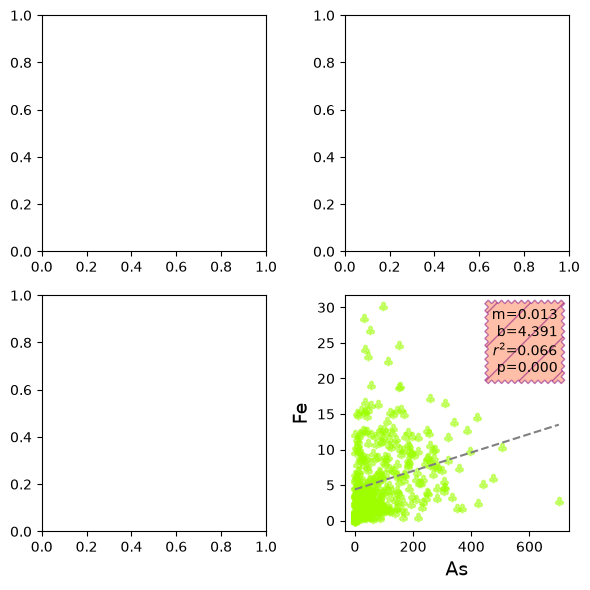

In [5]:
# Set and clean data
Xcolumn='As'
Ycolumn='Fe'
dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

# turn on plot
fig,ax=plt.subplots(2,2, layout='tight',figsize=(6,6))

# Scatter plot
ax[1,1].scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='xkcd:bright yellow green'
          ,marker=r'$\clubsuit$'
          ,label='Data')

# Regression
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax[1,1].plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax[1,1].set_xlabel(Xcolumn,fontsize=14)
ax[1,1].set_ylabel(Ycolumn,fontsize=14)

ax[1,1].text(0.95,0.95, textstr, transform=ax[1,1].transAxes
        ,fontsize=10 ,va='top',ha='right' ,bbox=props)     #add the text box

plt.show()

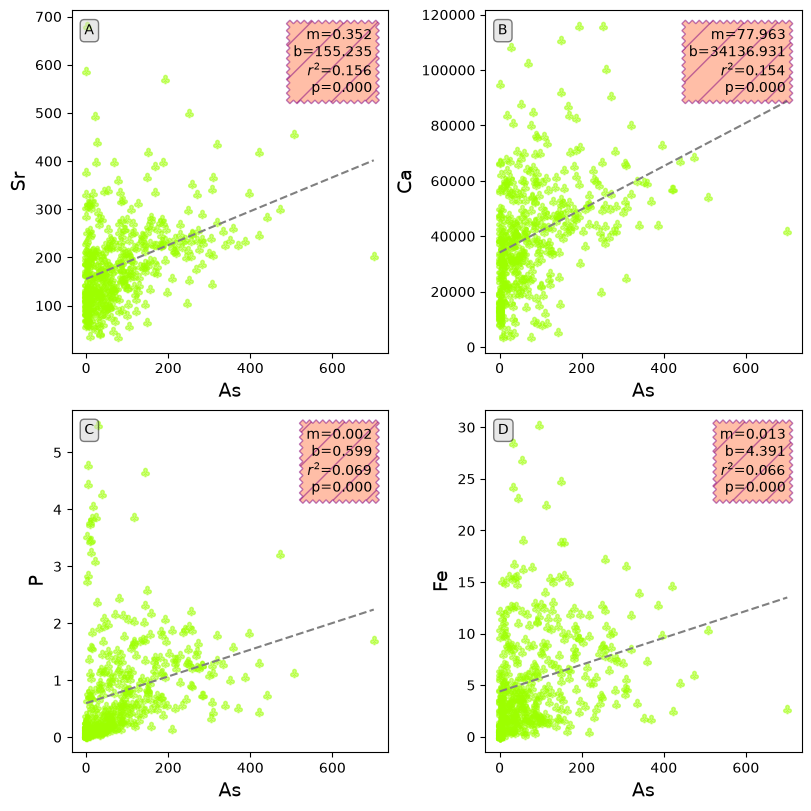

In [4]:
nrows=2
ncols=2

Xcolumn='As'
filename=f'Results/Plots_{nrows}_by_{ncols}.jpg'

# 2. Text box properties
props=dict(boxstyle='sawtooth,pad=0.5'
           ,facecolor='coral'
           ,edgecolor='purple'
           ,alpha=0.5
           , hatch='/')  #properties of the text box

props2=dict(boxstyle='round',facecolor='lightgrey',alpha=0.5)  #for the letters

fig,ax2d=plt.subplots(nrows,ncols,layout='constrained',figsize=(8,8))

for count, ax in enumerate(ax2d.flat):

    # Set and clean data
    Ycolumn=df_r2.iloc[count]["Ycolumn"]
    dfClean=df[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row
    
    # Scatter plot
    ax.scatter(dfClean[Xcolumn]
               ,dfClean[Ycolumn]
               ,alpha=0.5
               ,color='xkcd:bright yellow green'
              ,marker=r'$\clubsuit$'
              ,label='Data')
    
    # Regression
    LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
    textstr= (
        f'm={LinResult.slope:.3f}\n'
        f'b={LinResult.intercept:.3f}\n'
        f'$r^2$={LinResult.rvalue**2:.3f}\n'
        f'p={LinResult.pvalue:.3f}'
    )
    
    ## Best fit line
    x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
    y_fit = x_fit*LinResult.slope + LinResult.intercept
    
    ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')
    
    # Label Plot
    ax.set_xlabel(Xcolumn,fontsize=14)
    ax.set_ylabel(Ycolumn,fontsize=14)
    ax.text(0.95,0.95, textstr, transform=ax.transAxes
            ,fontsize=10 ,va='top',ha='right' ,bbox=props)     #add the text box
    ax.text(0.04,0.96,chr(count + ord('A'))
            ,transform=ax.transAxes,fontsize=10,va='top',ha='left'
            ,bbox=props2)                                      ## the letters

plt.show()
fig.savefig(filename,dpi=200,bbox_inches='tight')

### new page
<div style="page-break-before: always;"></div>


# Exit Ticket
## Name:
## uni:

### Q1. Does the XKCD comic dissuade you from p-hacking?  In 1-2 sentences explain why you are or are not okay with p-hacking.


<div style="page-break-before: always;"></div>
### Ignore.  For printing to pdf.  

In [9]:
%%html
<style>
@media print {
    body {
        zoom: 0.70; /* Scales everything down to 80% of original size */
    }
}
</style>

In [10]:
import ipynbname
from pypdf import PdfReader, PdfWriter

# Dynamically fetch the current notebook's name (without the .ipynb extension)
filename = ipynbname.name()

# Convert to PDF
!uv run jupyter nbconvert --to webpdf {filename}.ipynb \
    --log-level=CRITICAL \
    --WebPDFExporter.display_header_footer=True \
    --WebPDFExporter.header_template='<span></span>' \
    --WebPDFExporter.footer_template='<div style="font-size: 9pt; font-family: sans-serif; width: 100%; text-align: right; padding-right: 0.5in;"><span class="pageNumber"></span> of <span class="totalPages"></span></div>'

# Strip the last page
reader = PdfReader(f"{filename}.pdf")
writer = PdfWriter()
for page in reader.pages[:-1]:
    writer.add_page(page)
writer.write(f"{filename}.pdf")

(True, <_io.FileIO [closed]>)

In [11]:
from io import BytesIO
import time
import ipynbname
from ipylab import JupyterFrontEnd
from pypdf import PdfReader, PdfWriter
from reportlab.pdfgen import canvas

# 1. Force JupyterLab to save latest changes
app = JupyterFrontEnd()
app.commands.execute("docmanager:save")
time.sleep(1)

# 2. Get current notebook name
filename = ipynbname.name()

# 3. Convert notebook to PDF
!uv run jupyter nbconvert --to webpdf "{filename}.ipynb" --log-level=CRITICAL

# 4. Read PDF and isolate non-setup pages
reader = PdfReader(f"{filename}.pdf")
valid_pages = reader.pages[:-2]  # Strip final page
total_pages = len(valid_pages)


# Helper function to generate page number overlay
def create_footer_overlay(page_num, total, width, height):
  packet = BytesIO()
  c = canvas.Canvas(packet, pagesize=(width, height))
  c.setFont("Helvetica", 9)
  c.setFillColorRGB(0.3, 0.3, 0.3)  # Muted grey text

  # Stamp 0.5 inches (36pt) from bottom-right corner
  c.drawRightString(width - 36, 36, f"Page {page_num} of {total}")
  c.save()
  packet.seek(0)
  return PdfReader(packet).pages[0]


# 5. Stamp numbers and build final PDF
writer = PdfWriter()
for idx, page in enumerate(valid_pages, start=1):
  w = float(page.mediabox.width)
  h = float(page.mediabox.height)

  # Stamp page number onto the current page
  overlay = create_footer_overlay(idx, total_pages, w, h)
  page.merge_page(overlay)
  writer.add_page(page)

writer.write(f"{filename}.pdf")
print(
    f"Successfully generated {filename}.pdf ({total_pages} pages with page numbers)."
)

Successfully generated pandas-correlations.pdf (29 pages with page numbers).
